In [1]:
import cv2
import matplotlib.pyplot as plt
import os
import random

In [2]:
from datasets import load_dataset

ds = load_dataset("Teklia/IAM-line")

In [3]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 6482
    })
    validation: Dataset({
        features: ['image', 'text'],
        num_rows: 976
    })
    test: Dataset({
        features: ['image', 'text'],
        num_rows: 2915
    })
})


In [4]:
sample = ds["train"][0]

print("Text:", sample["text"])
sample["image"].show()

Text: put down a resolution on the subject


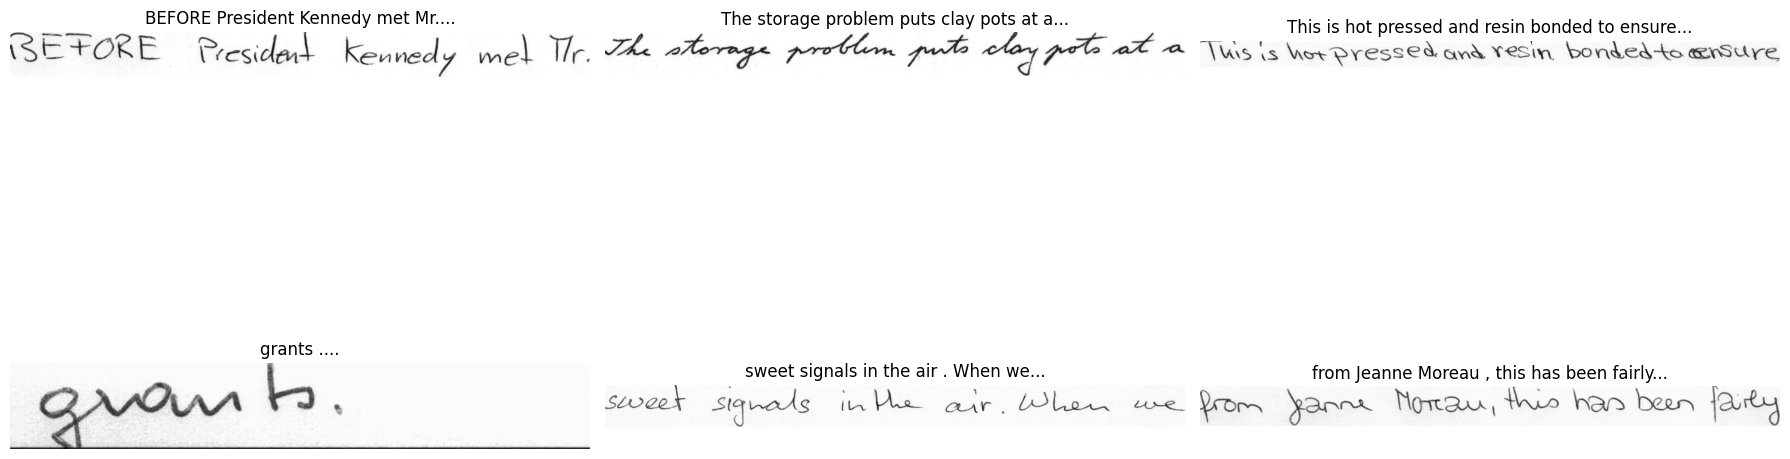

In [5]:
def show_random_samples(dataset, n=6):
    samples = random.sample(range(len(dataset)), n)
    plt.figure(figsize=(18, 10))

    for i, idx in enumerate(samples):
        sample = dataset[idx]
        plt.subplot(2, 3, i+1)
        plt.imshow(sample["image"], cmap="gray")
        plt.title(sample["text"][:50] + "...")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_random_samples(ds["train"])

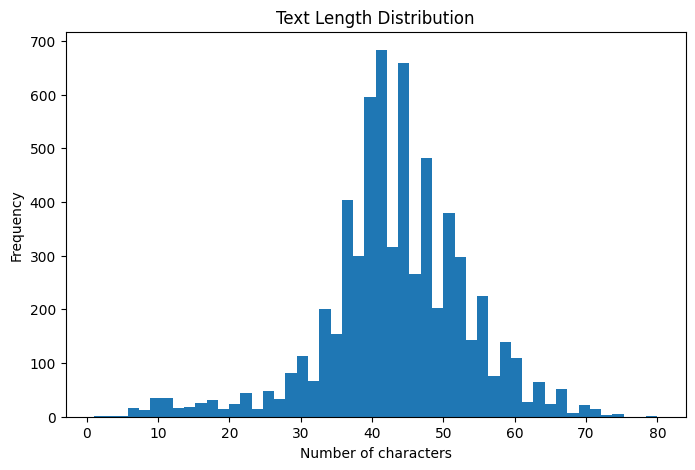

Min length: 1
Max length: 80
Average length: 43.38861462511571


In [6]:
import matplotlib.pyplot as plt

text_lengths = [len(sample["text"]) for sample in ds["train"]]

plt.figure(figsize=(8,5))
plt.hist(text_lengths, bins=50)
plt.xlabel("Number of characters")
plt.ylabel("Frequency")
plt.title("Text Length Distribution")
plt.show()

print("Min length:", min(text_lengths))
print("Max length:", max(text_lengths))
print("Average length:", sum(text_lengths)/len(text_lengths))


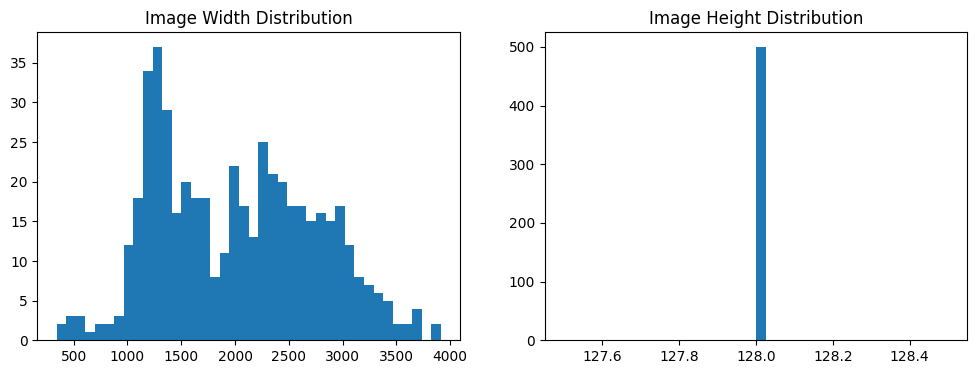

Height range: 128 - 128
Width range: 341 - 3913


In [7]:
heights = []
widths = []

for i in range(500):
    img = ds["train"][i]["image"]
    w, h = img.size
    widths.append(w)
    heights.append(h)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.hist(widths, bins=40)
plt.title("Image Width Distribution")

plt.subplot(1,2,2)
plt.hist(heights, bins=40)
plt.title("Image Height Distribution")

plt.show()

print("Height range:", min(heights), "-", max(heights))
print("Width range:", min(widths), "-", max(widths))


In [8]:
from collections import Counter

all_text = "".join([s["text"] for s in ds["train"]])
char_counts = Counter(all_text)

print("Total unique characters:", len(char_counts))
print("Characters:", sorted(char_counts.keys()))

Total unique characters: 79
Characters: [' ', '!', '"', '#', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [9]:
char_counts.most_common(10)

[(' ', 48629),
 ('e', 28050),
 ('t', 19796),
 ('a', 17620),
 ('o', 16008),
 ('n', 15562),
 ('i', 15237),
 ('r', 13869),
 ('s', 13752),
 ('h', 11938)]

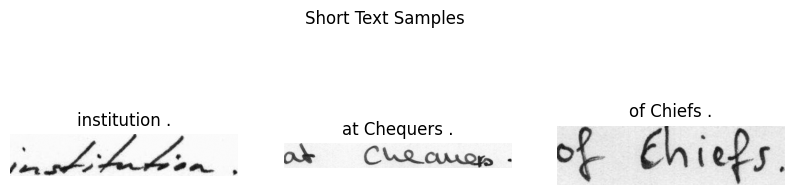

In [10]:
short = [s for s in ds["train"] if len(s["text"]) < 15][:3]
long = [s for s in ds["train"] if len(s["text"]) > 50][:3]

def show_group(samples, title):
    plt.figure(figsize=(10,3))
    for i, s in enumerate(samples):
        plt.subplot(1,3,i+1)
        plt.imshow(s["image"], cmap="gray")
        plt.title(s["text"][:25])
        plt.axis("off")
    plt.suptitle(title)
    plt.show()

show_group(short, "Short Text Samples")

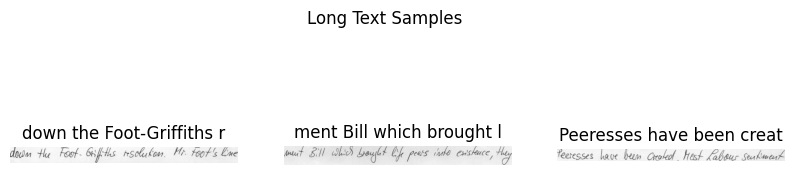

In [11]:
show_group(long, "Long Text Samples")

In [12]:
count = 0
count_1 = 0
for s in ds["train"]:
    w, h = s["image"].size
    if w > 128:
        count += 1
    else:
        count_1 += 1

print("Images narrower than or equal to 128:", count_1)
print("Images wider than 128:", count)

Images narrower than or equal to 128: 0
Images wider than 128: 6482


In [13]:
MAX_WIDTH = 160